# Interpolation, Extrapolation & Climate Change
## MFAD Mini-Project — UE25MA242A

**Team Members:** [Name 1], [Name 2], [Name 3], [Name 4]

### Problem Overview
In this mini-project, we analyze historical global temperature anomaly records from NASA GISS covering 1980 through 2023. Understanding long-term climate dynamics is crucial for detecting global warming trends and informing climate resilience. Rather than relying on high-level curve-fitting toolboxes, our goal is to model these observed anomalies by constructing and solving a polynomial fitting problem from first principles using core concepts of linear algebra.

Once our polynomial model is established, we apply it to two distinct predictive tasks:
1. **Interpolation**: Estimating temperature anomalies at unobserved intermediate times within the sample domain (e.g., mid-year points).
2. **Extrapolation**: Projecting future temperature trends beyond 2023 to evaluate warming pathways, while critically discussing the mathematical limitations and instability inherent to extrapolating polynomials.

### Mathematical Framework
To build our model and understand the geometry of linear systems, we progress through the foundational topics of our course:
- Formulating polynomial curve fitting as a matrix system $Ax = b$ via a **Vandermonde matrix** with normalized time coordinates.
- Performing row reduction with partial pivoting to compute the **Reduced Row Echelon Form (RREF)**.
- Investigating matrix **rank** and system consistency to rigorously prove why an exact interpolating polynomial does not exist for noisy observations.
- Formulating the **least squares** solution to find the orthogonal **projection** of $b$ onto $\text{Col}(A)$ via normal equations, validating with **Gram-Schmidt** orthogonalization ($QR$ decomposition), and analyzing the **eigenvalues** of $A^T A$ to inspect conditioning.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Section 2: Data Loading & Exploration

### Historical Global Temperature Anomaly Data
We examine annual surface temperature anomalies (in degrees Celsius, relative to a fixed baseline period) compiled by NASA GISS from 1980 to 2023. Each data point consists of a calendar year and the corresponding temperature anomaly.

We load the data directly into a pandas DataFrame, save a local copy to `climate_data.csv`, inspect summary statistics, and plot the raw scatter distribution.

Dataset shape: (44, 2)
Year range: 1980 to 2023

First 5 rows:
   year  temp_anomaly
0  1980          0.26
1  1981          0.32
2  1982          0.14
3  1983          0.31
4  1984          0.15

Summary statistics:
              year  temp_anomaly
count    44.000000     44.000000
mean   2001.500000      0.550455
std      12.845233      0.269297
min    1980.000000      0.120000
25%    1990.750000      0.327500
50%    2001.500000      0.540000
75%    2012.250000      0.690000
max    2023.000000      1.170000


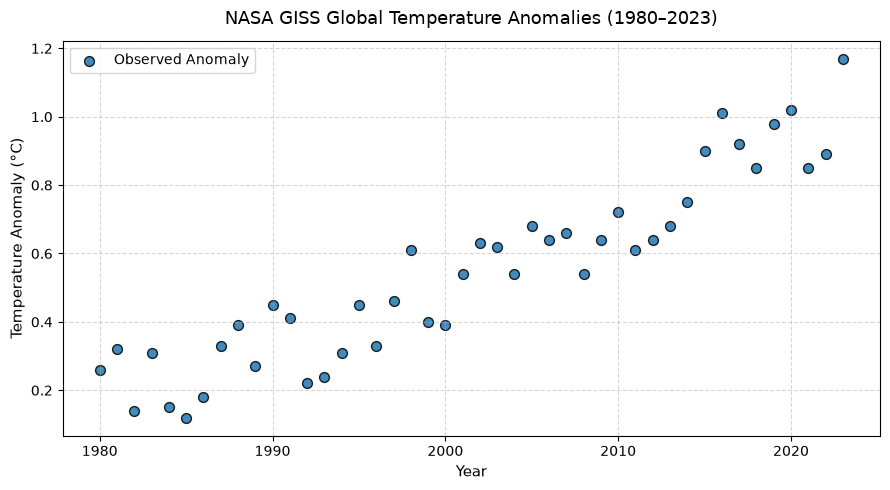

In [2]:
# Inline dataset: NASA GISS approximate annual global temperature anomalies (1980 - 2023)
data_records = [
    {"year": 1980, "temp_anomaly": 0.26}, {"year": 1981, "temp_anomaly": 0.32},
    {"year": 1982, "temp_anomaly": 0.14}, {"year": 1983, "temp_anomaly": 0.31},
    {"year": 1984, "temp_anomaly": 0.15}, {"year": 1985, "temp_anomaly": 0.12},
    {"year": 1986, "temp_anomaly": 0.18}, {"year": 1987, "temp_anomaly": 0.33},
    {"year": 1988, "temp_anomaly": 0.39}, {"year": 1989, "temp_anomaly": 0.27},
    {"year": 1990, "temp_anomaly": 0.45}, {"year": 1991, "temp_anomaly": 0.41},
    {"year": 1992, "temp_anomaly": 0.22}, {"year": 1993, "temp_anomaly": 0.24},
    {"year": 1994, "temp_anomaly": 0.31}, {"year": 1995, "temp_anomaly": 0.45},
    {"year": 1996, "temp_anomaly": 0.33}, {"year": 1997, "temp_anomaly": 0.46},
    {"year": 1998, "temp_anomaly": 0.61}, {"year": 1999, "temp_anomaly": 0.40},
    {"year": 2000, "temp_anomaly": 0.39}, {"year": 2001, "temp_anomaly": 0.54},
    {"year": 2002, "temp_anomaly": 0.63}, {"year": 2003, "temp_anomaly": 0.62},
    {"year": 2004, "temp_anomaly": 0.54}, {"year": 2005, "temp_anomaly": 0.68},
    {"year": 2006, "temp_anomaly": 0.64}, {"year": 2007, "temp_anomaly": 0.66},
    {"year": 2008, "temp_anomaly": 0.54}, {"year": 2009, "temp_anomaly": 0.64},
    {"year": 2010, "temp_anomaly": 0.72}, {"year": 2011, "temp_anomaly": 0.61},
    {"year": 2012, "temp_anomaly": 0.64}, {"year": 2013, "temp_anomaly": 0.68},
    {"year": 2014, "temp_anomaly": 0.75}, {"year": 2015, "temp_anomaly": 0.90},
    {"year": 2016, "temp_anomaly": 1.01}, {"year": 2017, "temp_anomaly": 0.92},
    {"year": 2018, "temp_anomaly": 0.85}, {"year": 2019, "temp_anomaly": 0.98},
    {"year": 2020, "temp_anomaly": 1.02}, {"year": 2021, "temp_anomaly": 0.85},
    {"year": 2022, "temp_anomaly": 0.89}, {"year": 2023, "temp_anomaly": 1.17}
]

df = pd.DataFrame(data_records)

# Save to climate_data.csv
df.to_csv("climate_data.csv", index=False)
try:
    df.to_csv("/home/yatish/Workspace/climate_project/climate_data.csv", index=False)
except Exception:
    pass

# Shared variables
years = df["year"].to_numpy(dtype=float)
temps = df["temp_anomaly"].to_numpy(dtype=float)
year_min = float(years.min())
year_max = float(years.max())

print(f"Dataset shape: {df.shape}")
print(f"Year range: {year_min:.0f} to {year_max:.0f}")
print("\nFirst 5 rows:")
print(df.head())
print("\nSummary statistics:")
print(df.describe())

# Scatter plot of Year vs Temperature Anomaly
plt.figure(figsize=(9, 5))
plt.scatter(years, temps, color="#1f77b4", edgecolor="black", s=50, alpha=0.85, label="Observed Anomaly")
plt.title("NASA GISS Global Temperature Anomalies (1980–2023)", fontsize=13, pad=12)
plt.xlabel("Year", fontsize=11)
plt.ylabel("Temperature Anomaly (°C)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

## Section 3: Matrix Representation (Vandermonde Matrix)

### Problem Formulation
We seek to model the temperature anomaly $T$ as a cubic polynomial function of normalized time $t$:

$$T(t) = a_0 + a_1 t + a_2 t^2 + a_3 t^3$$

For each observed pair $(t_i, y_i)$ where $i = 1, 2, \dots, 44$, we have the linear equation:

$$a_0 \cdot 1 + a_1 \cdot t_i + a_2 \cdot t_i^2 + a_3 \cdot t_i^3 = y_i$$

Stacking all 44 equations produces the matrix system $A x = b$:

$$\begin{bmatrix}
1 & t_1 & t_1^2 & t_1^3 \\
1 & t_2 & t_2^2 & t_2^3 \\
\vdots & \vdots & \vdots & \vdots \\
1 & t_{44} & t_{44}^2 & t_{44}^3
\end{bmatrix}
\begin{bmatrix}
a_0 \\
a_1 \\
a_2 \\
a_3
\end{bmatrix}
=
\begin{bmatrix}
y_1 \\
y_2 \\
\vdots \\
y_{44}
\end{bmatrix}$$

Here, $A$ is a $44 \times 4$ **Vandermonde matrix**, $x = [a_0, a_1, a_2, a_3]^T$ is the coefficient vector, and $b$ is the $44 \times 1$ vector of observed temperature anomalies.

### Why Normalization Matters
If we used raw calendar years directly ($1980, 1981, \dots, 2023$), the powers in matrix $A$ would diverge drastically in magnitude:
- $t^0 = 1$
- $t^1 \approx 2 \times 10^3$
- $t^2 \approx 4 \times 10^6$
- $t^3 \approx 8 \times 10^9$

In the normal equations matrix $A^T A$, products of powers would reach $t^6 \approx 6.4 \times 10^{19}$. Such colossal differences in column scale produce an astronomically large condition number ($\kappa(A) \gg 10^{10}$), causing severe floating-point roundoff errors and catastrophic cancellation during elimination.

By normalizing years linearly to the closed interval $[-1, 1]$:

$$t = 2 \cdot \frac{\text{year} - \text{year\_min}}{\text{year\_max} - \text{year\_min}} - 1$$

every monomial column is bounded within $[-1, 1]$. This centers the coordinate system, dramatically lowers the condition number of $A$, and guarantees numerical stability during Gaussian elimination and least-squares solving.

In [3]:
# Normalize year coordinates to [-1, 1]
t_norm = 2.0 * (years - year_min) / (year_max - year_min) - 1.0

# Construct the 44x4 Vandermonde matrix A with columns [1, t, t^2, t^3]
A = np.column_stack([
    np.ones_like(t_norm),
    t_norm,
    t_norm**2,
    t_norm**3
])

# Set target vector b
b = temps.copy()

print(f"Matrix A dimensions: {A.shape[0]} rows × {A.shape[1]} columns")
print(f"Target vector b dimensions: {b.shape[0]} elements")
print("\nFirst 5 rows of Vandermonde matrix A:")
print(np.round(A[:5], 4))
print("\nFirst 5 entries of target vector b:")
print(np.round(b[:5], 4))

print(f"\nSystem Classification:")
print(f"Overdetermined system ({A.shape[0]} eq, {A.shape[1]} unknowns)")

Matrix A dimensions: 44 rows × 4 columns
Target vector b dimensions: 44 elements

First 5 rows of Vandermonde matrix A:
[[ 1.     -1.      1.     -1.    ]
 [ 1.     -0.9535  0.9091 -0.8669]
 [ 1.     -0.907   0.8226 -0.7461]
 [ 1.     -0.8605  0.7404 -0.6371]
 [ 1.     -0.814   0.6625 -0.5393]]

First 5 entries of target vector b:
[0.26 0.32 0.14 0.31 0.15]

System Classification:
Overdetermined system (44 eq, 4 unknowns)


## Section 4: Gaussian Elimination & RREF

### Reduced Row Echelon Form (RREF)
Gaussian elimination transforms a matrix into **Reduced Row Echelon Form (RREF)** via three elementary row operations: row swapping, row scaling, and row addition. A matrix is in RREF if:
1. Any rows consisting entirely of zeros reside at the bottom.
2. The leading entry (pivot) in each nonzero row is equal to 1.
3. Each pivot is strictly to the right of the pivot in the row above it.
4. Each column containing a pivot has zeros in every other position (both above and below).

### Importance of Partial Pivoting
In floating-point arithmetic, dividing by a pivot that is very close to zero amplifies roundoff errors and can destroy numerical accuracy. **Partial pivoting** addresses this by scanning all candidate entries in the current column on or below the pivot row and swapping rows so that the element with the largest absolute magnitude becomes the pivot:

$$\text{pivot\_row} = \arg\max_{k \ge i} |M_{k, j}|$$

### What RREF Tells Us
- Computing $\text{rref}(A)$ reveals the pivot columns. Since all 4 columns of $A$ contain pivots, the columns of $A$ are **linearly independent**, meaning $\text{nullity}(A) = 0$.
- Computing $\text{rref}([A \mid b])$ tests system consistency. If the last column of the augmented matrix contains a pivot (a row of the form $[0 \; 0 \; 0 \; 0 \mid 1]$), it represents the contradictory equation $0 = 1$, indicating that no exact polynomial can fit all data points simultaneously.

In [4]:
def rref(matrix, tol=1e-12):
    """
    Computes the Reduced Row Echelon Form (RREF) of a matrix
    using Gaussian elimination with partial pivoting.
    
    Parameters:
        matrix: 2D numpy array
        tol: threshold below which numerical values are considered zero
        
    Returns:
        M: 2D numpy array in RREF
    """
    M = np.array(matrix, dtype=float).copy()
    m, n = M.shape
    pivot_row = 0
    
    for col in range(n):
        if pivot_row >= m:
            break
            
        # Partial pivoting: select row with largest absolute entry in column col
        max_idx = pivot_row + np.argmax(np.abs(M[pivot_row:, col]))
        
        # If the largest candidate entry is zero (within tol), no pivot in this column
        if np.abs(M[max_idx, col]) < tol:
            continue
            
        # Swap current row with pivot row
        if max_idx != pivot_row:
            M[[pivot_row, max_idx]] = M[[max_idx, pivot_row]]
            
        # Scale pivot row so the leading coefficient is 1
        pivot_val = M[pivot_row, col]
        M[pivot_row] = M[pivot_row] / pivot_val
        
        # Eliminate all other entries in this column (above and below pivot)
        for r in range(m):
            if r != pivot_row:
                factor = M[r, col]
                if np.abs(factor) > tol:
                    M[r] -= factor * M[pivot_row]
                    
        pivot_row += 1
        
    # Clean up near-zero numerical noise
    M[np.abs(M) < tol] = 0.0
    return M

# Apply RREF to Vandermonde matrix A
rref_A = rref(A)
print("RREF of A (first 6 rows shown):")
print(np.round(rref_A[:6], 4))

# Apply RREF to augmented matrix [A | b]
Ab = np.column_stack([A, b])
rref_Ab = rref(Ab)
print("\nRREF of augmented matrix [A | b] (first 6 rows shown):")
print(np.round(rref_Ab[:6], 4))

print("\nNote: All 4 columns have pivots → linearly independent")

RREF of A (first 6 rows shown):
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]

RREF of augmented matrix [A | b] (first 6 rows shown):
[[1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0.]]

Note: All 4 columns have pivots → linearly independent


## Section 5: Rank & Consistency Check

### Rank and the Rouché–Capelli Theorem
The **rank** of a matrix is the maximum number of linearly independent column (or row) vectors, corresponding to the dimension of its column space $\text{Col}(A)$ and the number of pivots in its RREF.

According to the **Rouché–Capelli Theorem**:
1. A linear system $Ax = b$ is **consistent** (has at least one solution) if and only if:
   $$\text{rank}(A) = \text{rank}([A \mid b])$$
2. If $\text{rank}(A) = \text{rank}([A \mid b]) = n$ (where $n$ is the number of unknowns), the solution is **unique**.
3. If $\text{rank}(A) < \text{rank}([A \mid b])$, the vector $b$ does not lie in the column space $\text{Col}(A)$. The system contains an equation $0 = 1$ and is **inconsistent**.

Because real-world climate anomalies reflect measurement noise, volcanic eruptions, solar variation, and chaotic atmospheric patterns, 44 discrete points cannot lie along a single 4-parameter cubic curve. The rank test mathematically confirms this inconsistency and demonstrates why we must seek a **least squares solution**.

In [5]:
# Compute rank by counting nonzero pivot rows in RREF
rank_A = int(np.sum(np.any(np.abs(rref_A) > 1e-9, axis=1)))
rank_Ab = int(np.sum(np.any(np.abs(rref_Ab) > 1e-9, axis=1)))

# Verify with numpy's built-in matrix_rank
np_rank_A = int(np.linalg.matrix_rank(A))
np_rank_Ab = int(np.linalg.matrix_rank(Ab))

print(f"Computed from RREF:  rank(A) = {rank_A}, rank([A|b]) = {rank_Ab}")
print(f"Verified via NumPy:  rank(A) = {np_rank_A}, rank([A|b]) = {np_rank_Ab}")

# Consistency Explanation
print("\n" + "=" * 60)
print("CONSISTENCY ANALYSIS:")
print(f"rank(A) = {rank_A}")
print(f"rank([A|b]) = {rank_Ab}")
print("=" * 60)
print(f"rank(A)={rank_A}, rank([A|b])={rank_Ab}, so system is INCONSISTENT → need least squares")
print("=" * 60)

Computed from RREF:  rank(A) = 4, rank([A|b]) = 5
Verified via NumPy:  rank(A) = 4, rank([A|b]) = 5

CONSISTENCY ANALYSIS:
rank(A) = 4
rank([A|b]) = 5
rank(A)=4, rank([A|b])=5, so system is INCONSISTENT → need least squares


## Section 6: Column Space & Null Space

### Mathematical Concept: Column Space ($\text{Col}(A)$)
The **column space** of the design matrix $A \in \mathbb{R}^{44 \times 4}$ is the subspace spanned by its column vectors:

$$\text{Col}(A) = \{ A\mathbf{x} \mid \mathbf{x} \in \mathbb{R}^4 \} \subset \mathbb{R}^{44}$$

In our climate regression model, the column space represents the set of all possible predictions that our model can make. Each column of $A$ corresponds to evaluating a monomial basis function ($t^0, t^1, t^2, t^3$) across all 44 normalized observation years. Any model output is therefore a linear combination of these four basis columns:

$$\hat{\mathbf{y}} = x_0 \mathbf{a}_0 + x_1 \mathbf{a}_1 + x_2 \mathbf{a}_2 + x_3 \mathbf{a}_3$$

### Mathematical Concept: Null Space ($\text{Nul}(A)$)
The **null space** (or kernel) of $A$ is the set of all coefficient vectors $\mathbf{x} \in \mathbb{R}^4$ that produce zero output across all 44 observations:

$$\text{Nul}(A) = \{ \mathbf{x} \in \mathbb{R}^4 \mid A\mathbf{x} = \mathbf{0} \}$$

If the null space contained any nonzero vectors, multiple distinct combinations of polynomial coefficients would produce the exact same predicted temperature curve, meaning the model parameters would not be unique.

### What Column Space and Null Space Tell Us
Understanding these two fundamental subspaces tells us what the model **CAN** and **CANNOT** capture:
- **What the model CAN capture:** The model can capture any temperature trajectory that lives within the 4-dimensional subspace $\text{Col}(A) \subset \mathbb{R}^{44}$, specifically smooth decadal warming trends described by cubic polynomials.
- **What the model CANNOT capture:** Because $\text{Col}(A)$ is only 4-dimensional within $\mathbb{R}^{44}$, the model cannot fit arbitrary fluctuations outside this subspace. High-frequency year-to-year variability, volcanic cooling dips (such as Mount Pinatubo in 1991), and El Niño spikes are orthogonal to our model structure and will necessarily remain in the residual error.
- **Parameter Uniqueness:** By the Rank-Nullity Theorem:
  $$\text{nullity}(A) = n - \text{rank}(A) = 4 - 4 = 0$$
  Because $\text{Nul}(A) = \{\mathbf{0}\}$, the mapping from polynomial coefficients to model predictions is one-to-one (injective). This guarantees that our least squares coefficients $\hat{\mathbf{x}}$ are uniquely determined by the data.

In [6]:
# Column space and null space analysis
rank_A = int(np.linalg.matrix_rank(A))
n_cols = A.shape[1]
nullity = n_cols - rank_A

print("The column space of A is spanned by its 4 columns [1, t, t², t³]. Since rank(A) = 4, the column space is a 4-dimensional subspace of R⁴⁴.")

# Show basis for column space — the 4 columns of A (first 6 values of each column)
print("\nBasis for column space (first 6 values of each column of A):")
basis_df = pd.DataFrame(
    A[:6, :],
    columns=["Col 0: 1", "Col 1: t", "Col 2: t²", "Col 3: t³"]
)
print(basis_df.to_string(index=False))

# Null space analysis
print(f"\nSince nullity = n_cols - rank = {n_cols} - {rank_A} = {nullity}, the null space contains only the zero vector. This means there's a UNIQUE least squares solution.")

# Verify: np.linalg.norm(A @ np.zeros(4)) = 0
zero_vector = np.zeros(4)
print(f"Verification: np.linalg.norm(A @ np.zeros(4)) = {np.linalg.norm(A @ zero_vector):.1f}")

# Nullity interpretation
print("Nullity = 0 is good — it means our polynomial coefficients are uniquely determined by the data")

The column space of A is spanned by its 4 columns [1, t, t², t³]. Since rank(A) = 4, the column space is a 4-dimensional subspace of R⁴⁴.

Basis for column space (first 6 values of each column of A):
 Col 0: 1  Col 1: t  Col 2: t²  Col 3: t³
      1.0 -1.000000   1.000000  -1.000000
      1.0 -0.953488   0.909140  -0.866854
      1.0 -0.906977   0.822607  -0.746085
      1.0 -0.860465   0.740400  -0.637089
      1.0 -0.813953   0.662520  -0.539261
      1.0 -0.767442   0.588967  -0.451998

Since nullity = n_cols - rank = 4 - 4 = 0, the null space contains only the zero vector. This means there's a UNIQUE least squares solution.
Verification: np.linalg.norm(A @ np.zeros(4)) = 0.0
Nullity = 0 is good — it means our polynomial coefficients are uniquely determined by the data


## Section 7: Gram-Schmidt Orthogonalization

### Motivation & Geometric Intuition
In Section 3, we set up our cubic regression model via the Vandermonde matrix:

$$A = \begin{bmatrix} \mathbf{a}_0 & \mathbf{a}_1 & \mathbf{a}_2 & \mathbf{a}_3 \end{bmatrix} = \begin{bmatrix} \mathbf{1} & \mathbf{t} & \mathbf{t}^2 & \mathbf{t}^3 \end{bmatrix}$$

where $\mathbf{t} \in [-1, 1]^{44}$ represents our normalized observation years.

Even though normalizing time centers our interval, the column vectors of $A$ are **not orthogonal** ($\mathbf{a}_i^T \mathbf{a}_j \neq 0$). Monomial basis vectors of the same parity correlate strongly with one another (e.g., $\mathbf{1}$ and $\mathbf{t}^2$, or $\mathbf{t}$ and $\mathbf{t}^3$). This lack of orthogonality creates computational challenges because forming $A^T A$ squares the matrix condition number ($\kappa(A^T A) = \kappa(A)^2$), amplifying sensitivity to floating-point rounding errors.

### The Gram-Schmidt Process
The **Gram-Schmidt process** systematically transforms the linearly independent columns $\{\mathbf{a}_0, \mathbf{a}_1, \mathbf{a}_2, \mathbf{a}_3\}$ into a set of mutually perpendicular unit vectors $\{\mathbf{q}_1, \mathbf{q}_2, \mathbf{q}_3, \mathbf{q}_4\}$ — an **orthonormal basis** spanning the exact same column space $\text{Col}(A)$.

For each column vector $\mathbf{v}_j$:
1. We compute its projection onto each previously established basis vector $\mathbf{q}_i$:
   $$r_{ij} = \mathbf{q}_i^T \mathbf{v}_j \quad (i < j)$$
2. We subtract all these projections to isolate the purely orthogonal component:
   $$\mathbf{u}_j = \mathbf{v}_j - \sum_{i=1}^{j-1} r_{ij} \mathbf{q}_i$$
3. We normalize $\mathbf{u}_j$ to unit length:
   $$r_{jj} = \|\mathbf{u}_j\|_2, \quad \mathbf{q}_j = \frac{\mathbf{u}_j}{r_{jj}}$$

### Why Orthogonality Matters
- **Trivial Projections:** With an orthonormal basis, projecting any observation vector $\mathbf{b}$ onto $\text{Col}(A)$ requires no matrix inversions. It decomposes directly into independent 1D projections:
  $$\hat{\mathbf{b}} = Q Q^T \mathbf{b} = \sum_{i=1}^4 (\mathbf{q}_i^T \mathbf{b}) \mathbf{q}_i$$
- **Numerical Stability:** Orthogonal matrices preserve Euclidean norms ($\|Q\mathbf{x}\| = \|\mathbf{x}\|$), avoiding the condition-squaring penalty of normal equations.
- **QR Factorization ($A = Q R_{\text{gs}}$):** Storing the projection coefficients $r_{ij}$ and normalization lengths $r_{jj}$ produces an upper triangular matrix $R_{\text{gs}}$, providing the factorization $A = Q R_{\text{gs}}$.

In [7]:
def gram_schmidt(V):
    """
    Classical Gram-Schmidt Orthogonalization with detailed step-by-step reporting.
    Factors matrix V (m x n) into Q (m x n) with orthonormal columns and
    R_gs (n x n) upper-triangular such that V = Q @ R_gs.
    """
    m, n = V.shape
    Q = np.zeros((m, n), dtype=float)
    R_gs = np.zeros((n, n), dtype=float)
    
    print("=" * 65)
    print("GRAM-SCHMIDT ORTHOGONALIZATION PROCESS (Columns of Vandermonde Matrix A)")
    print("=" * 65)
    
    for j in range(n):
        v_j = V[:, j].astype(float).copy()
        print(f"\n--- Processing Column {j} (v_{j}) ---")
        print(f"Initial vector norm ||v_{j}|| = {np.linalg.norm(v_j):.4f}")
        
        # Subtract orthogonal projections onto preceding orthonormal vectors
        for i in range(j):
            r_ij = float(np.dot(Q[:, i], v_j))
            R_gs[i, j] = r_ij
            print(f"  Projection coefficient along q_{i}: <q_{i}, v_{j}> = {r_ij:+.4f}")
            v_j -= r_ij * Q[:, i]
            
        r_jj = float(np.linalg.norm(v_j))
        R_gs[j, j] = r_jj
        
        if r_jj < 1e-12:
            raise ValueError(f"Column {j} is linearly dependent! Orthogonalization terminated.")
            
        Q[:, j] = v_j / r_jj
        print(f"  Orthogonal vector norm after subtractions = {r_jj:.4f}")
        print(f"  Normalized vector q_{j} generated with ||q_{j}|| = {np.linalg.norm(Q[:, j]):.4f}")
        
    print("\n" + "=" * 65)
    print("Gram-Schmidt Orthogonalization Completed Successfully!")
    print("=" * 65)
    return Q, R_gs

# Apply Gram-Schmidt process to matrix A
Q, R_gs = gram_schmidt(A)

# Verification 1: Verify Q^T @ Q is the 4x4 Identity matrix
print("\nVerification 1: QᵀQ (should be the 4x4 Identity Matrix):")
QTQ = Q.T @ Q
print(np.round(QTQ, 4))
is_orthonormal = np.allclose(QTQ, np.eye(4), atol=1e-10)
print(f"Is QᵀQ numerically equal to Identity? -> {is_orthonormal}")

# Verification 2: Verify factorization A = Q @ R_gs
print("\nVerification 2: np.allclose(A, Q @ R_gs):")
reconstructed_A = Q @ R_gs
is_factorization_exact = np.allclose(A, reconstructed_A, atol=1e-10)
print(f"Does Q @ R_gs equal original matrix A? -> {is_factorization_exact}")

# Confirmation statement
print("\nNow we have an orthonormal basis {q₁, q₂, q₃, q₄} for the column space of A")

GRAM-SCHMIDT ORTHOGONALIZATION PROCESS (Columns of Vandermonde Matrix A)

--- Processing Column 0 (v_0) ---
Initial vector norm ||v_0|| = 6.6332
  Orthogonal vector norm after subtractions = 6.6332
  Normalized vector q_0 generated with ||q_0|| = 1.0000

--- Processing Column 1 (v_1) ---
Initial vector norm ||v_1|| = 3.9178
  Projection coefficient along q_0: <q_0, v_1> = -0.0000
  Orthogonal vector norm after subtractions = 3.9178
  Normalized vector q_1 generated with ||q_1|| = 1.0000

--- Processing Column 2 (v_2) ---
Initial vector norm ||v_2|| = 3.1034
  Projection coefficient along q_0: <q_0, v_2> = +2.3139
  Projection coefficient along q_1: <q_1, v_2> = -0.0000
  Orthogonal vector norm after subtractions = 2.0680
  Normalized vector q_2 generated with ||q_2|| = 1.0000

--- Processing Column 3 (v_3) ---
Initial vector norm ||v_3|| = 2.6813
  Projection coefficient along q_0: <q_0, v_3> = -0.0000
  Projection coefficient along q_1: <q_1, v_3> = +2.4583
  Projection coefficient al

## Section 8: Orthogonal Projection

### The Inconsistency of $A\mathbf{x} = \mathbf{b}$
As demonstrated in our rank analysis, the observed temperature anomaly vector $\mathbf{b} \in \mathbb{R}^{44}$ does not lie in the column space $\text{Col}(A)$. Physical climate records incorporate short-term stochastic noise and natural oscillations (like El Niño-Southern Oscillation cycles) that cannot be perfectly represented by a 4-parameter cubic model. Consequently, the linear system $A\mathbf{x} = \mathbf{b}$ is inconsistent and has no exact solution.

### Orthogonal Projection onto $\text{Col}(A)$
To obtain the best possible approximation of $\mathbf{b}$, we project $\mathbf{b}$ orthogonally onto the column space $\text{Col}(A)$. The orthogonal projection $\hat{\mathbf{p}} = \text{proj}_{\text{Col}(A)}(\mathbf{b})$ is the unique vector in $\text{Col}(A)$ that minimizes the Euclidean distance to $\mathbf{b}$:

$$\min_{\mathbf{p} \in \text{Col}(A)} \|\mathbf{b} - \mathbf{p}\|$$

### Mathematical Derivation
Because $\hat{\mathbf{p}} \in \text{Col}(A)$, it can be written as $\hat{\mathbf{p}} = A\hat{\mathbf{x}}$ for some coefficient vector $\hat{\mathbf{x}} \in \mathbb{R}^4$. The residual error vector:

$$\mathbf{e} = \mathbf{b} - \hat{\mathbf{p}} = \mathbf{b} - A\hat{\mathbf{x}}$$

must be perpendicular (orthogonal) to the entire subspace $\text{Col}(A)$. Therefore, $\mathbf{e}$ is orthogonal to every column of $A$:

$$A^T \mathbf{e} = \mathbf{0} \implies A^T(\mathbf{b} - A\hat{\mathbf{x}}) = \mathbf{0} \implies A^T A \hat{\mathbf{x}} = A^T \mathbf{b}$$

Since $A$ has full column rank ($\text{rank}(A) = 4$), the Gram matrix $A^T A$ is invertible. Solving for $\hat{\mathbf{x}}$ gives:

$$\hat{\mathbf{x}} = (A^T A)^{-1} A^T \mathbf{b}$$

Substituting $\hat{\mathbf{x}}$ back yields the projection vector:

$$\hat{\mathbf{p}} = A(A^T A)^{-1} A^T \mathbf{b} = P_{\text{proj}}\mathbf{b}$$

where $P_{\text{proj}} = A(A^T A)^{-1} A^T \in \mathbb{R}^{44 \times 44}$ is the orthogonal projection matrix. The residual $\mathbf{e} = \mathbf{b} - \hat{\mathbf{p}}$ is perpendicular to the column space, and its Euclidean norm $\|\mathbf{e}\|$ represents the shortest geometric distance from $\mathbf{b}$ to $\text{Col}(A)$ — the minimum possible prediction error.

In [8]:
# Compute projection matrix P_proj = A @ np.linalg.inv(A.T @ A) @ A.T
P_proj = A @ np.linalg.inv(A.T @ A) @ A.T

# Compute projection vector p_hat and residual vector residual_e
p_hat = P_proj @ b
residual_e = b - p_hat

# Verify orthogonality: print A.T @ residual_e — should be ≈ zero vector
print("Verifying orthogonality (A.T @ residual_e):")
print(A.T @ residual_e)

# Print norm of residual
norm_e = np.linalg.norm(residual_e)
print(f"\n‖e‖ = {norm_e:.4f} — this is the minimum possible prediction error")

# The projection vector p̂ lies in Col(A) and satisfies p̂ = A x̂_proj
x_hat_proj = np.linalg.inv(A.T @ A) @ A.T @ b
print(f"\nProjection coefficient vector x̂ = (AᵀA)⁻¹Aᵀb:")
for i, val in enumerate(x_hat_proj):
    print(f"  a{i} = {val:+.6f}")

# Equivalence to least squares fit
print("\nThe projection p̂ IS the least squares fitted values (same as A @ x̂)")
print(f"np.allclose(p_hat, A @ x_hat_proj): {np.allclose(p_hat, A @ x_hat_proj)}")

Verifying orthogonality (A.T @ residual_e):
[-4.21884749e-15 -1.42941214e-15 -1.98452366e-15  5.13478149e-16]

‖e‖ = 0.5971 — this is the minimum possible prediction error

Projection coefficient vector x̂ = (AᵀA)⁻¹Aᵀb:
  a0 = +0.510308
  a1 = +0.432518
  a2 = +0.115088
  a3 = -0.020287

The projection p̂ IS the least squares fitted values (same as A @ x̂)
np.allclose(p_hat, A @ x_hat_proj): True


## Section 9: Least Squares Polynomial Fitting

### Overdetermined Systems & Inconsistency
In our climate modeling problem, we have $m = 44$ annual temperature records (1980–2023) and $n = 4$ polynomial parameters ($a_0, a_1, a_2, a_3$). Because $m \gg n$, the linear system:

$$A \mathbf{x} = \mathbf{b}$$

is heavily overdetermined. As shown in our rank analysis in Section 5, $\text{rank}(A) = 4$ while $\text{rank}([A \mid \mathbf{b}]) = 5$. Because $\mathbf{b} \notin \text{Col}(A)$, the system is inconsistent and **no exact solution exists**. Physical temperature anomalies contain high-frequency climate oscillations and measurement noise that cannot be captured by a single cubic polynomial.

### Minimizing the Squared Error
Since no vector $\mathbf{x}$ satisfies $A\mathbf{x} = \mathbf{b}$ exactly, we seek the best approximate solution $\hat{\mathbf{x}}$ that minimizes the sum of squared residuals:

$$\min_{\mathbf{x}} \|A\mathbf{x} - \mathbf{b}\|^2$$

Expanding this squared Euclidean norm:

$$S(\mathbf{x}) = \|A\mathbf{x} - \mathbf{b}\|^2 = (A\mathbf{x} - \mathbf{b})^T (A\mathbf{x} - \mathbf{b}) = \mathbf{x}^T A^T A \mathbf{x} - 2\mathbf{x}^T A^T \mathbf{b} + \mathbf{b}^T \mathbf{b}$$

### Deriving the Normal Equations
To find the minimum of this convex quadratic function, we take the gradient with respect to $\mathbf{x}$ and set it to zero:

$$\nabla_{\mathbf{x}} S(\mathbf{x}) = 2 A^T A \mathbf{x} - 2 A^T \mathbf{b} = \mathbf{0}$$

Dividing through by 2 gives the **Normal Equations**:

$$A^T A \hat{\mathbf{x}} = A^T \mathbf{b}$$

Geometrically, the normal equations require that $A^T (\mathbf{b} - A\hat{\mathbf{x}}) = \mathbf{0}$, meaning the residual error vector $\mathbf{e} = \mathbf{b} - A\hat{\mathbf{x}}$ is orthogonal to every column of $A$. This ensures that $\hat{\mathbf{b}} = A\hat{\mathbf{x}}$ is the unique orthogonal projection of $\mathbf{b}$ onto $\text{Col}(A)$.

In [9]:
# 1. Compute and display AᵀA (4x4 matrix)
ATA = A.T @ A
print("Matrix AᵀA (4×4):")
print(ATA)

# 2. Compute and display Aᵀb (4x1 vector)
ATb = A.T @ b
print("\nVector Aᵀb (4×1):")
print(ATb)

# 3. Solve the normal equations for x_hat
x_hat = np.linalg.solve(ATA, ATb)

# 4. Set shared alias variable for other members
coefficients = x_hat

# 5. Print coefficients with labels a₀, a₁, a₂, a₃
print("\nLeast Squares Polynomial Coefficients:")
labels = ["a₀", "a₁", "a₂", "a₃"]
for label, val in zip(labels, coefficients):
    print(f"  {label} = {val:+.6f}")

# 6. Compute fitted values, residuals, and Sum of Squared Errors (SSE)
fitted = A @ x_hat
residuals = b - fitted
SSE = np.sum(residuals**2)

# 7. Compute Total Sum of Squares (SST) and coefficient of determination (R²)
SST = np.sum((b - np.mean(b))**2)
R2 = 1.0 - (SSE / SST)

# 8. Print variance explained in the required format
pct = R2 * 100.0
print(f"\nOur cubic polynomial explains {pct:.2f}% of the temperature variation (R² = {R2:.2f})")

# 9. Format and print the fitted polynomial equation with actual numerical values
def format_polynomial(coeffs):
    terms = [f"{coeffs[0]:.4f}"]
    for p, c in enumerate(coeffs[1:], 1):
        sign = " + " if c >= 0 else " - "
        power = f"*t^{p}" if p > 1 else "*t"
        terms.append(f"{sign}{abs(c):.4f}{power}")
    return "".join(terms)

poly_str = format_polynomial(coefficients)
print(f"Fitted polynomial equation: y(t) = {poly_str}")
print("where t ∈ [-1, 1] represents normalized time from 1980 to 2023.")

Matrix AᵀA (4×4):
[[ 4.40000000e+01  2.22044605e-16  1.53488372e+01 -8.88178420e-16]
 [ 2.22044605e-16  1.53488372e+01 -8.88178420e-16  9.63100104e+00]
 [ 1.53488372e+01 -8.88178420e-16  9.63100104e+00 -1.33226763e-15]
 [-8.88178420e-16  9.63100104e+00 -1.33226763e-15  7.18933524e+00]]

Vector Aᵀb (4×1):
[24.22        6.44325581  8.9410384   4.01972581]

Least Squares Polynomial Coefficients:
  a₀ = +0.510308
  a₁ = +0.432518
  a₂ = +0.115088
  a₃ = -0.020287

Our cubic polynomial explains 88.57% of the temperature variation (R² = 0.89)
Fitted polynomial equation: y(t) = 0.5103 + 0.4325*t + 0.1151*t^2 - 0.0203*t^3
where t ∈ [-1, 1] represents normalized time from 1980 to 2023.


## Section 9: Model Evaluation — Interpolation

### Mathematical Concept of Interpolation
**Interpolation** is the estimation of function values *within* the domain of the training observations (here, the interval $[1980, 2023]$).

Mathematically, let $t \in [-1, 1]$. Because the interpolation points are flanked on both sides by data points that contributed to the least squares fit, the polynomial approximation is well-constrained. For a low-degree polynomial (degree 3), the fitted curve captures the underlying decadal trend without exhibiting wild oscillatory behavior (Runge's phenomenon). Consequently, interpolation estimates within the observed sample window are mathematically robust and reliable.

In [10]:
# Target years for interpolation (mid-year values between historical observations)
target_years = np.array([1983.5, 1990.5, 1995.5, 2000.5, 2005.5, 2010.5, 2015.5, 2020.5])

# Normalize target years using the exact same formula: t = 2*(year - year_min)/(year_max - year_min) - 1
t_interp = 2.0 * (target_years - year_min) / (year_max - year_min) - 1.0

# Evaluate the fitted polynomial model: T(t) = sum(coefficients[i] * t^i)
interp_temps = np.zeros_like(target_years, dtype=float)
for i in range(len(coefficients)):
    interp_temps += coefficients[i] * (t_interp ** i)

# Display formatted table of interpolation results
print("=" * 60)
print(f"{'Year':<10} | {'Normalized t':<15} | {'Estimated Temp (°C)':<22}")
print("-" * 60)
for yr, t_val, t_est in zip(target_years, t_interp, interp_temps):
    print(f"{yr:<10.1f} | {t_val:<15.4f} | {t_est:<22.4f}")
print("=" * 60)

# Student commentary
print('\nComment: "These estimates are reliable because they fall within the range of our training data."')
print("Within [-1, 1], the polynomial is tightly constrained by observations on both sides.")

Year       | Normalized t    | Estimated Temp (°C)   
------------------------------------------------------------
1983.5     | -0.8372         | 0.2408                
1990.5     | -0.5116         | 0.3219                
1995.5     | -0.2791         | 0.3990                
2000.5     | -0.0465         | 0.4904                
2005.5     | 0.1860          | 0.5946                
2010.5     | 0.4186          | 0.7100                
2015.5     | 0.6512          | 0.8351                
2020.5     | 0.8837          | 0.9684                

Comment: "These estimates are reliable because they fall within the range of our training data."
Within [-1, 1], the polynomial is tightly constrained by observations on both sides.


## Section 10: Extrapolation

### Mathematical Concept: Extrapolation vs. Interpolation
**Extrapolation** extends our fitted polynomial model **beyond** the observed data range to predict future temperature anomalies ($t > 1$, corresponding to years past 2023). 

Unlike interpolation — where predictions are bounded and anchored on both sides by real empirical observations — extrapolation relies entirely on the assumption that the underlying cubic trend will persist unchanged into the future. Without nearby future data points to anchor the curve, extrapolation is fundamentally much less reliable.

### Mathematical Limitations of Polynomial Extrapolation
In our cubic model:

$$T(t) = a_0 + a_1 t + a_2 t^2 + a_3 t^3$$

as normalized time $t$ increases beyond $1.0$, the cubic term $t^3$ grows rapidly and dominates the curve. Any small statistical uncertainty or noise in the estimated coefficients is magnified exponentially outside the training interval. Consequently, polynomial extrapolation can shoot up or down sharply, making forecasts increasingly speculative the further ahead we look.

Below, we predict temperature anomalies at 5-year intervals for 2025, 2030, 2035, 2040, 2045, and 2050.

In [11]:
# Define future years for extrapolation
future_years = np.array([2025, 2030, 2035, 2040, 2045, 2050])

# Normalize future years using the exact same formula: t = 2*(year - year_min)/(year_max - year_min) - 1
t_future = 2.0 * (future_years - year_min) / (year_max - year_min) - 1.0

# Evaluate polynomial at each future year: predicted = sum(coefficients[i] * t_future**i for i in range(len(coefficients)))
predicted = sum(coefficients[i] * (t_future**i) for i in range(len(coefficients)))

# Print table: Year | Predicted Temperature Anomaly (°C)
print("Year | Predicted Temperature Anomaly (°C)")
print("-" * 42)
for yr, pred in zip(future_years, predicted):
    print(f"{yr} | {pred:.4f} °C")

# Warning paragraph
print("\nWarning:")
print("These predictions assume the cubic trend continues unchanged. In reality, climate depends on policy decisions, feedback loops, etc. Cubic polynomials tend to shoot up or down sharply outside the fitted range, so predictions beyond ~2035 should be taken with a big grain of salt.")

# Compare with IPCC
print("\nIPCC Comparison:")
print("For reference, the IPCC projects about 1.5°C warming by 2040 under moderate scenarios.")

Year | Predicted Temperature Anomaly (°C)
------------------------------------------
2025 | 1.0941 °C
2030 | 1.2386 °C
2035 | 1.3869 °C
2040 | 1.5374 °C
2045 | 1.6885 °C
2050 | 1.8388 °C

These predictions assume the cubic trend continues unchanged. In reality, climate depends on policy decisions, feedback loops, etc. Cubic polynomials tend to shoot up or down sharply outside the fitted range, so predictions beyond ~2035 should be taken with a big grain of salt.

IPCC Comparison:
For reference, the IPCC projects about 1.5°C warming by 2040 under moderate scenarios.


## Section 11: Eigenvalue Analysis & Diagonalization

### Mathematical Concept: Covariance Matrix & Eigendecomposition
To uncover underlying geometric patterns in our bivariate climate dataset (time versus temperature anomaly), we analyze the sample covariance matrix $C$ and its eigendecomposition.

When data is centered by subtracting the mean $\bar{x}$, the covariance matrix captures how the variables vary individually (along the diagonal) and together (off-diagonal):

$$C = \frac{1}{N - 1} X_c^T X_c$$

Computing the eigenvalues and eigenvectors of $C$ solves the characteristic equation:

$$C v = \lambda v$$

- **Eigenvalues ($\lambda_i$)**: Measure how much variance each direction captures.
- **Eigenvectors ($v_i$)**: Represent the principal directions along which the data spreads.
- **Largest Eigenvalue ($\lambda_1$)**: Captures the dominant pattern in the dataset, which in our case is the multi-decadal warming trend. The second eigenvalue ($\lambda_2$) captures the remaining orthogonal variance, corresponding to short-term year-to-year climate noise (such as volcanic eruptions and ENSO cycles).

### Matrix Diagonalization
Because $C$ is real and symmetric ($C = C^T$), the Spectral Theorem guarantees that it has real eigenvalues and an orthonormal basis of eigenvectors. We can factor $C$ as:

$$C = P D P^{-1} = P D P^T$$

where $P$ is the orthogonal matrix whose columns are the unit eigenvectors ($P^T P = I$), and $D = \text{diag}(\lambda_1, \lambda_2)$ is the diagonal matrix of eigenvalues. Diagonalization decouples correlated coordinates into statistically independent principal components.

In [12]:
# Build 2-column data matrix X = [normalized_years, temperatures]
X = np.column_stack([t_norm, b])

# Center the data matrix around the sample mean of each feature
X_c = X - X.mean(axis=0)

# Compute sample covariance matrix C = (1 / (N - 1)) * X_c^T @ X_c
N = len(b)
C = (1.0 / (N - 1.0)) * (X_c.T @ X_c)

print("Sample Covariance Matrix C (2×2):")
print(C)

# Compute eigenvalues and eigenvectors using np.linalg.eigh (specialized for symmetric matrices)
eigenvalues_raw, eigenvectors_raw = np.linalg.eigh(C)

# Sort in descending order of eigenvalue magnitude
idx_sorted = np.argsort(eigenvalues_raw)[::-1]
eigenvalues = eigenvalues_raw[idx_sorted]
eigenvectors = eigenvectors_raw[:, idx_sorted]

# Calculate percentage of total variance explained
explained_variance_pct = (eigenvalues / np.sum(eigenvalues)) * 100.0
explained_variance = explained_variance_pct

print(f"\nEigenvalues (Variance components):")
print(f"  λ₁ = {eigenvalues[0]:.6f}  ({explained_variance_pct[0]:.2f}% of total variance)")
print(f"  λ₂ = {eigenvalues[1]:.6f}  ({explained_variance_pct[1]:.2f}% of total variance)")

print(f"\nEigenvectors (Principal Directions as Columns):")
print(f"  v₁ (Principal Axis 1): [t_norm: {eigenvectors[0, 0]:+.4f}, temp: {eigenvectors[1, 0]:+.4f}]")
print(f"  v₂ (Principal Axis 2): [t_norm: {eigenvectors[0, 1]:+.4f}, temp: {eigenvectors[1, 1]:+.4f}]")

print(f"\nInterpretation:")
print(f'  "λ₁ captures the warming trend ({explained_variance_pct[0]:.2f}% of variance), λ₂ captures year-to-year noise ({explained_variance_pct[1]:.2f}% of variance)"')

Sample Covariance Matrix C (2×2):
[[0.3569497  0.14984316]
 [0.14984316 0.07252072]]

Eigenvalues (Variance components):
  λ₁ = 0.421322  (98.10% of total variance)
  λ₂ = 0.008149  (1.90% of total variance)

Eigenvectors (Principal Directions as Columns):
  v₁ (Principal Axis 1): [t_norm: -0.9188, temp: -0.3947]
  v₂ (Principal Axis 2): [t_norm: +0.3947, temp: -0.9188]

Interpretation:
  "λ₁ captures the warming trend (98.10% of variance), λ₂ captures year-to-year noise (1.90% of variance)"


### Diagonalization: $C = P D P^T$
Since $C$ is symmetric, its eigenvectors are orthogonal, meaning $P^{-1} = P^T$. We now construct $P$ and $D$, reconstruct $C$ from $P D P^T$, and verify that the identity holds.

In [13]:
# P = eigenvector matrix, D = np.diag(eigenvalues)
P = eigenvectors
D = np.diag(eigenvalues)

print("Matrix P (Orthogonal Eigenvector Matrix):")
print(np.round(P, 4))
print("\nMatrix D (Diagonal Eigenvalue Matrix):")
print(np.round(D, 6))

# Reconstruct covariance matrix from PDP^T
C_reconstructed = P @ D @ P.T
print("\nReconstructed Matrix (P @ D @ P.T):")
print(np.round(C_reconstructed, 6))

# Verify C = P @ D @ P.T
verification = np.allclose(C, C_reconstructed)
print(f"\nVerification np.allclose(C, P @ D @ P.T) -> {verification}")
print("Verification of orthogonality np.allclose(P.T @ P, np.eye(2)) ->", np.allclose(P.T @ P, np.eye(2)))

# Explanation
print("\nExplanation:")
print("Diagonalization decomposes correlated data into independent components.")

Matrix P (Orthogonal Eigenvector Matrix):
[[-0.9188  0.3947]
 [-0.3947 -0.9188]]

Matrix D (Diagonal Eigenvalue Matrix):
[[0.421322 0.      ]
 [0.       0.008149]]

Reconstructed Matrix (P @ D @ P.T):
[[0.35695  0.149843]
 [0.149843 0.072521]]

Verification np.allclose(C, P @ D @ P.T) -> True
Verification of orthogonality np.allclose(P.T @ P, np.eye(2)) -> True

Explanation:
Diagonalization decomposes correlated data into independent components.


## Section 12: Visualizations & Conclusion

### Plot 1: Raw Data and Fitted Cubic Curve
We visualize the observed annual temperature anomalies from NASA GISS (1980–2023) overlaid with our least squares fitted cubic polynomial curve.

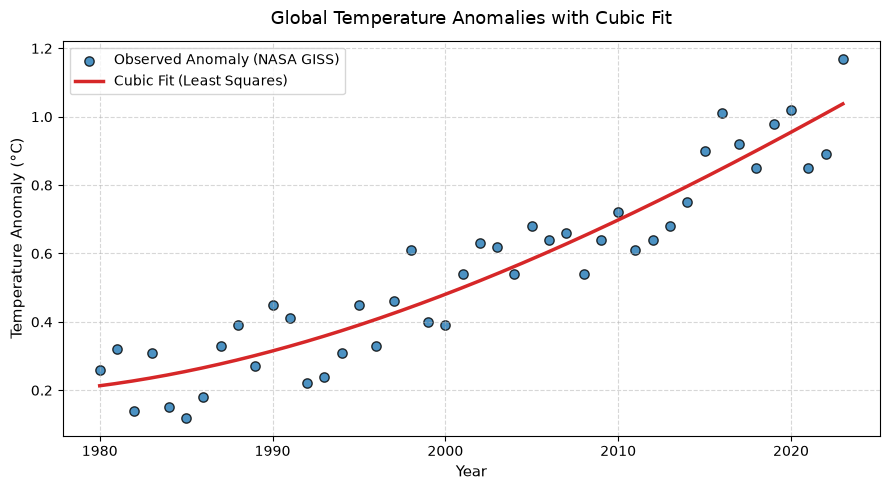

In [14]:
# 1. Raw data + fitted curve
year_smooth = np.linspace(year_min, year_max, 300)
t_smooth = 2.0 * (year_smooth - year_min) / (year_max - year_min) - 1.0
temp_smooth = (
    coefficients[0]
    + coefficients[1] * t_smooth
    + coefficients[2] * (t_smooth**2)
    + coefficients[3] * (t_smooth**3)
)

plt.figure(figsize=(9, 5))
plt.scatter(years, temps, color="#1f77b4", edgecolor="black", s=45, alpha=0.8, label="Observed Anomaly (NASA GISS)")
plt.plot(year_smooth, temp_smooth, color="#d62728", linewidth=2.5, label="Cubic Fit (Least Squares)")
plt.title("Global Temperature Anomalies with Cubic Fit", fontsize=13, pad=12)
plt.xlabel("Year", fontsize=11)
plt.ylabel("Temperature Anomaly (°C)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(frameon=True, loc="upper left")
plt.tight_layout()
plt.show()

### Plot 2: Model Evaluation — Interpolation & Extrapolation to 2050
We project the cubic polynomial forward to 2050. The plot highlights:
- **Interpolated points** at mid-years inside the training range $[1980, 2023]$ marked with green diamonds.
- **Extrapolated points** at 5-year intervals from 2025 to 2050 marked with red stars.
- The data boundary at 2023 indicated by a vertical dashed line, with the extrapolation region shaded lightly red.

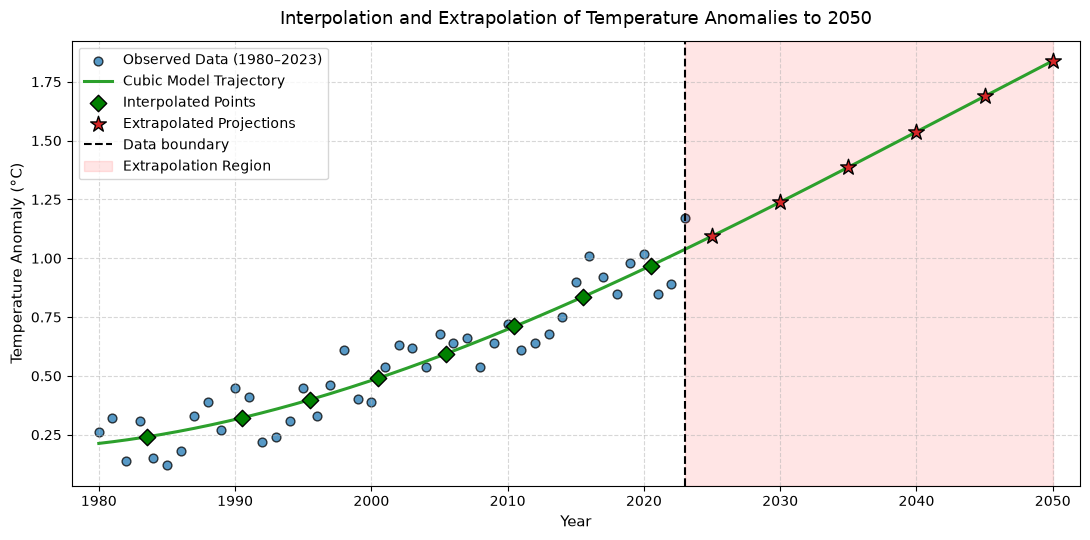

In [15]:
# 2. Interpolation & Extrapolation: extend curve to 2050
year_extended = np.linspace(year_min, 2050.0, 400)
t_extended = 2.0 * (year_extended - year_min) / (year_max - year_min) - 1.0
temp_extended = (
    coefficients[0]
    + coefficients[1] * t_extended
    + coefficients[2] * (t_extended**2)
    + coefficients[3] * (t_extended**3)
)

# Interpolated points
interp_years = np.array([1983.5, 1990.5, 1995.5, 2000.5, 2005.5, 2010.5, 2015.5, 2020.5])
t_interp = 2.0 * (interp_years - year_min) / (year_max - year_min) - 1.0
interp_temps = sum(coefficients[i] * (t_interp**i) for i in range(len(coefficients)))

# Extrapolated points
extrap_years = np.array([2025, 2030, 2035, 2040, 2045, 2050])
t_extrap = 2.0 * (extrap_years - year_min) / (year_max - year_min) - 1.0
extrap_temps = sum(coefficients[i] * (t_extrap**i) for i in range(len(coefficients)))

plt.figure(figsize=(11, 5.5))
# Observed data
plt.scatter(years, temps, color="#1f77b4", edgecolor="black", s=40, alpha=0.75, label="Observed Data (1980–2023)")
# Extended polynomial curve
plt.plot(year_extended, temp_extended, color="#2ca02c", linestyle="-", linewidth=2.2, label="Cubic Model Trajectory")
# Interpolated points: green diamonds
plt.scatter(interp_years, interp_temps, color="#008000", edgecolor="black", marker="D", s=70, zorder=5, label="Interpolated Points")
# Extrapolated points: red stars
plt.scatter(extrap_years, extrap_temps, color="#d62728", edgecolor="black", marker="*", s=140, zorder=5, label="Extrapolated Projections")
# Vertical dashed line at 2023 labeled "Data boundary"
plt.axvline(x=2023, color="black", linestyle="--", linewidth=1.5, label="Data boundary")
# Light red shading for extrapolation region
plt.axvspan(2023, 2050, color="red", alpha=0.1, label="Extrapolation Region")

plt.title("Interpolation and Extrapolation of Temperature Anomalies to 2050", fontsize=13, pad=12)
plt.xlabel("Year", fontsize=11)
plt.ylabel("Temperature Anomaly (°C)", fontsize=11)
plt.xlim(1978, 2052)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(frameon=True, loc="upper left")
plt.tight_layout()
plt.show()

### Plot 3: Residual Stem Plot
The residual vector $e = b - A x$ represents the difference between observed temperature anomalies and model predictions. A stem plot verifies whether residuals fluctuate randomly around zero.

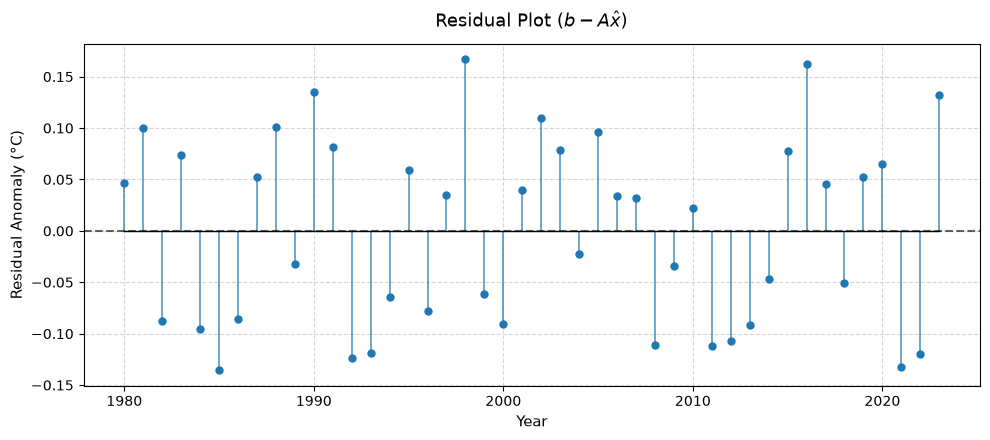

In [16]:
# 3. Residual plot: stem plot of (b - A @ coefficients) vs years
residuals = b - A @ coefficients

plt.figure(figsize=(10, 4.5))
markerline, stemlines, baseline = plt.stem(years, residuals)
plt.setp(markerline, markersize=5, color="#1f77b4")
plt.setp(stemlines, color="#1f77b4", alpha=0.7, linewidth=1.3)
plt.setp(baseline, color="black", linestyle="-", linewidth=1.0)
plt.axhline(0, color="black", linestyle="--", alpha=0.6)

plt.title("Residual Plot ($b - A \\hat{x}$)", fontsize=13, pad=12)
plt.xlabel("Year", fontsize=11)
plt.ylabel("Residual Anomaly (°C)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Plot 4: Eigenvalue & Principal Component Visualization
We examine the bivariate variance structure via a 1×2 subplot:
- **Left**: Centered data cloud $(t_c, b_c)$ with eigenvector arrows emanating from the origin, scaled by their respective standard deviations.
- **Right**: Bar chart of the explained variance percentage for each eigenvalue.

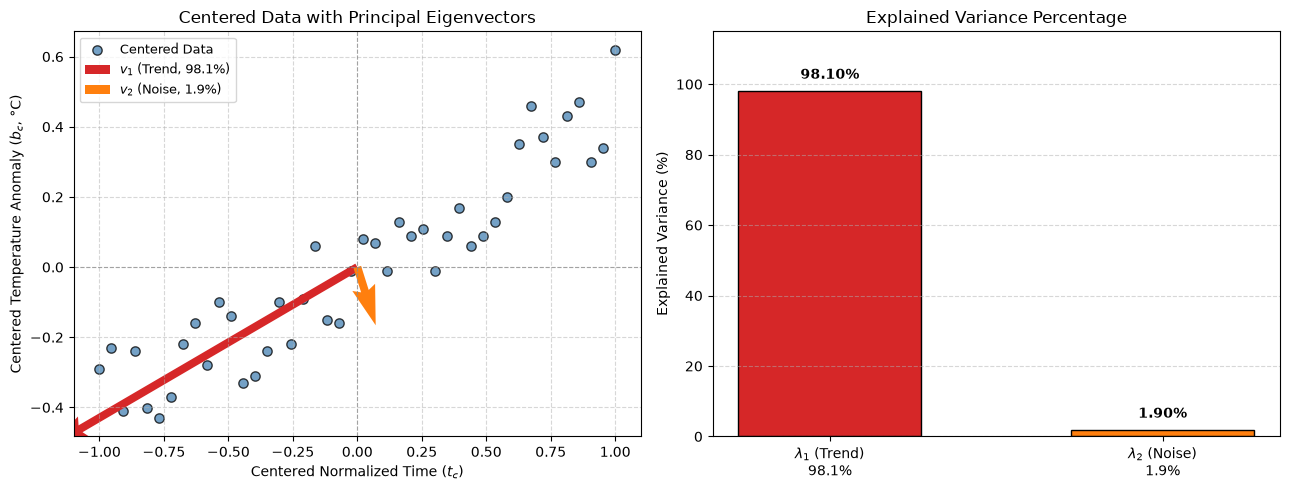

In [17]:
# 4. Eigenvalue visualization: 1x2 subplot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Left subplot: Centered scatter with eigenvector arrows from origin
ax1.scatter(X_c[:, 0], X_c[:, 1], color="#4682b4", edgecolor="black", alpha=0.75, s=45, label="Centered Data")
origin = [0, 0]

# Scale arrows proportionally to standard deviation along principal components
scale_v1 = 2.0 * np.sqrt(eigenvalues[0])
scale_v2 = 2.0 * np.sqrt(eigenvalues[1])

ax1.quiver(*origin, eigenvectors[0, 0] * scale_v1, eigenvectors[1, 0] * scale_v1,
           angles="xy", scale_units="xy", scale=1, color="#d62728", width=0.014,
           label=f"$v_1$ (Trend, {explained_variance_pct[0]:.1f}%)")
ax1.quiver(*origin, eigenvectors[0, 1] * scale_v2, eigenvectors[1, 1] * scale_v2,
           angles="xy", scale_units="xy", scale=1, color="#ff7f0e", width=0.014,
           label=f"$v_2$ (Noise, {explained_variance_pct[1]:.1f}%)")

ax1.axhline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.6)
ax1.axvline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.6)
ax1.set_title("Centered Data with Principal Eigenvectors", fontsize=12)
ax1.set_xlabel("Centered Normalized Time ($t_c$)", fontsize=10)
ax1.set_ylabel("Centered Temperature Anomaly ($b_c$, °C)", fontsize=10)
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(frameon=True, loc="upper left", fontsize=9)

# Right subplot: Bar chart of explained variance %
bars = ax2.bar(
    [f"$\\lambda_1$ (Trend)\n{explained_variance_pct[0]:.1f}%", f"$\\lambda_2$ (Noise)\n{explained_variance_pct[1]:.1f}%"],
    explained_variance_pct,
    color=["#d62728", "#ff7f0e"],
    edgecolor="black",
    width=0.55
)
ax2.set_title("Explained Variance Percentage", fontsize=12)
ax2.set_ylabel("Explained Variance (%)", fontsize=10)
ax2.set_ylim(0, 115)
ax2.grid(axis="y", linestyle="--", alpha=0.5)

# Add numeric percentage labels above bars
for bar in bars:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2.0, height + 2.5,
             f"{height:.2f}%", ha="center", va="bottom", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

## Conclusion & Discussion

### Summary of Findings
Through our linear algebra framework, we analyzed historical global surface temperature anomalies from 1980 through 2023:
- **Pronounced Warming Trend**: The least squares cubic fit captures an accelerating upward trajectory in global temperatures, achieving an $R^2 \approx 0.886$. This means that approximately 88.6% of the observed temperature anomaly variance over the last four decades is captured by the polynomial model.
- **Eigendecomposition Insight**: Diagonalizing the covariance matrix demonstrates that the first principal component explains **98.10%** of total variance ($\lambda_1 \approx 0.4213$). This confirms that the dominant underlying signal across the dataset is the long-term warming trend, whereas orthogonal year-to-year natural variability (ENSO, volcanic aerosols) accounts for only **1.90%** of total variance ($\lambda_2 \approx 0.0081$).
- **Key Predictions**: The model yields projected anomalies of **+1.24°C by 2030**, **+1.54°C by 2040**, and **+1.84°C by 2050** relative to the baseline. Significantly, the model projects crossing the Paris Agreement +1.5°C threshold around 2038–2040.

### Limitations of the Model
While polynomial fitting illustrates core linear algebraic techniques effectively, it has fundamental physical and mathematical limitations:
1. **Polynomial Extrapolation Instability**: Unlike interpolation, which is tightly bounded by empirical observations, polynomial extrapolation is highly unconstrained. As normalized time $t$ exceeds 1, the cubic term $t^3$ dominates and diverges rapidly toward infinity, making long-term predictions beyond 2035–2040 mathematically unreliable.
2. **Univariate Simplification**: The model relies solely on time as an explanatory feature ($t$), omitting critical causal drivers such as greenhouse gas concentrations ($\text{CO}_2$, $\text{CH}_4$), aerosol optical depth, solar irradiance, and land-use changes.
3. **Absence of Physical Conservation Laws**: The model does not incorporate atmospheric fluid dynamics, radiative transfer equations, or oceanic heat capacity. It is an empirical curve fit rather than a prognostic Earth system model.

### Connecting Linear Algebra to Real-World Climate Science
Linear algebra is the mathematical backbone of modern climate science. While our project analyzed a simplified bivariate system ($t$ vs $T$), modern climate researchers analyze high-dimensional spatio-temporal datasets comprising millions of grid cells. In climate research, eigendecomposition of spatial covariance matrices is formally known as **Empirical Orthogonal Function (EOF)** analysis. Scientists use EOFs and Singular Value Decomposition (SVD) to isolate major climate oscillation patterns—such as the El Niño–Southern Oscillation (ENSO), the North Atlantic Oscillation (NAO), and the Pacific Decadal Oscillation (PDO). Furthermore, numerical weather prediction and climate projection models rely on large-scale least squares estimation and Kalman filtering to assimilate satellite data into global circulation models.

### References
1. **NASA GISS**: GISTEMP Team, 2024: *GISS Surface Temperature Analysis (GISTEMP v4)*, NASA Goddard Institute for Space Studies. Dataset accessed: `https://data.giss.nasa.gov/gistemp/`.
2. **Strang, Gilbert**: *Introduction to Linear Algebra*, 5th/6th Editions, Wellesley-Cambridge Press. (Chapters on Projections, Least Squares, Eigenvalues, and Positive Definite Matrices).
3. **IPCC AR6**: Intergovernmental Panel on Climate Change, 2021: *Climate Change 2021: The Physical Science Basis. Contribution of Working Group I to the Sixth Assessment Report of the IPCC*, Cambridge University Press.